In [12]:
from nnAudio.features.cqt import CQT
import torch
import math
from matplotlib import pyplot as plt
import numpy as np
import lightning as L
import scipy
from collections import Counter
import librosa
import torchaudio

from murenn import MuReNNDirect,DTCWT,IDTCWT


In [13]:
HYPERPARAMS = {
    "sr": 16000,
    "seg_length": 1024,
    "win_length": 400,
    "n_mels": 4,
    "f_min": 4000,
    "f_max": 8000,
    "hop_length": 256,
    "n_samples": 5000,
}
mel_params = {
            "sample_rate": HYPERPARAMS["sr"],
            "n_fft": 1024, #512+1 bins
            "win_length": HYPERPARAMS["win_length"],
            "hop_length": HYPERPARAMS["hop_length"],
            "f_min": HYPERPARAMS["f_min"],
            "f_max": HYPERPARAMS["f_max"],
            "n_mels": HYPERPARAMS["n_mels"], #averange o
            "center": False,
            "power": 2.0
        }
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
teacher = torchaudio.transforms.MelSpectrogram(**mel_params)
mel_fbank = teacher.mel_scale.fb #nb_bins*nb_mels tensor

Counter({1: 2, 0: 2})

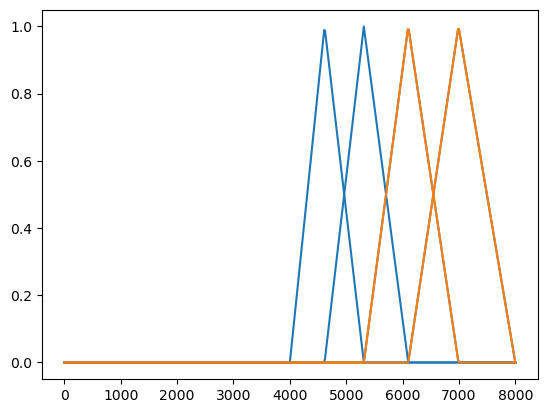

In [14]:
mel_scale = "htk"
# set x axis scale
m_min = torchaudio.functional.functional._hz_to_mel(
    teacher.f_min, mel_scale=mel_scale)
m_max = torchaudio.functional.functional._hz_to_mel(
    teacher.f_max, mel_scale=mel_scale)
# in mel scale
m_pts = torch.linspace(m_min, m_max, teacher.n_mels + 2)
# in freq(Hz) scale
f_pts = torchaudio.functional.functional._mel_to_hz(
    m_pts, mel_scale=mel_scale)
center_freqs = f_pts[1:-1]
nyquist = teacher.sample_rate / 2
octaves = np.round(np.log2(
    nyquist / center_freqs.numpy())).astype("int") # Nyquist/2**(j+1)<epsilon_j<Nyquist/2**(j), with j>1 -->log_2^(Nyquist/epsilon_j)-1<j<log_2^(Nyquist/epsilon_j)
Q_ctr = Counter(octaves) # filter per scale, sum = n_mels
J_psi = max(Q_ctr)+1
boundaries = [0] + list(np.cumsum([Q_ctr[j] for j in range(J_psi)])) + [len(octaves)]
omega = np.linspace(0, teacher.sample_rate//2, mel_fbank.shape[0], endpoint=True)
for j in range(J_psi):
    psi_octave = mel_fbank[:, boundaries[j]:boundaries[j+2]]
    plt.plot(omega, psi_octave, color=col[j]);

HYPERPARAMS["n_octave"] = J_psi
HYPERPARAMS["octaves"] = Q_ctr
Q_ctr

In [15]:
class SineData(torch.utils.data.Dataset):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.fmax = spec["f_max"]
        self.fmin = spec["f_min"]
        self.freqs = np.logspace(
            np.log2(self.fmin),
            np.log2(self.fmax),
            spec["n_samples"],
            base=2.0,
            endpoint=False,
        )
        self.seg_length = spec["seg_length"]
        self.sr = spec["sr"]

        mel_params = {
                    "sample_rate": HYPERPARAMS["sr"],
                    "n_fft": 1024, #512+1 bins
                    "win_length": HYPERPARAMS["win_length"],
                    "hop_length": HYPERPARAMS["hop_length"],
                    "f_min": HYPERPARAMS["f_min"],
                    "f_max": HYPERPARAMS["f_max"],
                    "n_mels": HYPERPARAMS["n_mels"], #averange o
                    "center": False,
                    "power": 2.0
                }
        self.closure = torchaudio.transforms.MelSpectrogram(**mel_params)
    
    def __getitem__(self, idx):
        freq = self.freqs[idx]
        t = torch.arange(self.seg_length)/self.sr
        x = torch.sin(2*math.pi*freq*t)
        y = self.closure(x)
        return freq, x, y

    def __len__(self):
        return len(self.freqs)

In [16]:
data = SineData(HYPERPARAMS)
for item in data[0]:
    print(type(item))
    print(item.shape)

<class 'numpy.float64'>
()
<class 'torch.Tensor'>
torch.Size([1024])
<class 'torch.Tensor'>
torch.Size([4, 1])


In [17]:
class SineDataModule(L.LightningDataModule):
    def __init__(self, batch_size=32, num_workers=0):
        super().__init__()
        self.batch_size = batch_size
        self.num_workers = num_workers

    def setup(self, stage=None):
        spec = HYPERPARAMS
        dataset = SineData(spec)
        n_train = int(0.8*len(dataset))
        n_val = int(0.1*len(dataset))
        n_test = len(dataset) - n_train - n_val
        split = torch.utils.data.random_split(dataset, [n_train, n_val, n_test])
        self.train_dataset, self.val_dataset, self.test_dataset = split

    def train_dataloader(self):
        return torch.utils.data.DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            num_workers=self.num_workers,
            shuffle=True,
        )

    def val_dataloader(self):
        return torch.utils.data.DataLoader(
            self.val_dataset,
            batch_size=self.batch_size,
            num_workers=self.num_workers,
            shuffle=False,
        )

    def test_dataloader(self):
        return torch.utils.data.DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            num_workers=self.num_workers,
            shuffle=False,
        )

In [18]:
class Student(L.LightningModule):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []
        self.loss = torch.nn.MSELoss()
        # self.loss = torch.nn.CosineSimilarity(dim=-1)
        x = torch.zeros(1,1,spec["seg_length"])
        x[:,:,x.shape[-1]//2] = 1
        self.x = x

    def step(self, batch, fold):
        feat = batch[2]
        x = batch[1]
        Sx, _ = self.forward(x)
        n_feat = feat.shape[-1]
        n_pred = Sx.shape[-1]
        N = min(n_feat, n_pred)
        # print(feat.shape)
        # print(Sx.shape)
        # criterion = torch.nn.MSELoss()
        # loss = criterion(outputs[:,:,:N], feat[:,:,:N])
        # loss = 0.5 * (1-self.loss(Sx[:,:,:N], feat[:,:,:N]).mean())
        loss = self.loss(Sx, feat)
        if fold == "train":
            self.train_outputs.append(loss)
        elif fold == "test":
            self.test_outputs.append(loss)
        elif fold == "val":
            self.val_outputs.append(loss)
        return {'loss': loss}

    def get_imp_fig(self):
        fig = plt.figure()
        self.eval()
        Sx, Yx = self(self.x)
        omega = np.linspace(0, self.spec["sr"], self.x.shape[-1]//2)
        fig = plt.figure();
        for j, Yx_j in enumerate(Yx):
            for c in range(Yx_j.shape[1]):
                path = Yx_j.detach().numpy()[:, c, :]
                path = scipy.signal.resample(path, self.x.shape[-1]//2, axis=-1)
                path_hat = np.fft.fft(path, axis=-1)
                plt.plot(omega, np.abs(path_hat[:, :].T), color=col[j]);
        plt.xlim(0, teacher.sample_rate)
        self.train()
        return fig

    def training_step(self, batch, batch_idx):
        return self.step(batch, "train")
    
    def validation_step(self, batch, batch_idx):
        return self.step(batch, "val")

    def test_step(self, batch, batch_idx):
        return self.step(batch, "test")
    
    def on_train_epoch_start(self):
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []

    def on_train_epoch_end(self):
        avg_loss = torch.tensor(self.train_outputs).mean()
        self.log('train_loss', avg_loss, prog_bar=False)
    
    def on_test_epoch_end(self):
        avg_loss = torch.tensor(self.test_outputs).mean()
        self.log('test_loss', avg_loss, prog_bar=False)

    def on_validation_epoch_end(self):
        avg_loss = torch.tensor(self.val_outputs).mean()
        fig = self.get_imp_fig()
        tensorboard = self.logger.experiment
        tensorboard.add_figure("imp response", fig, global_step = self.trainer.global_step)
        tensorboard.close()
        self.log('val_loss', avg_loss, prog_bar=False)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters())

In [19]:
class MuReNN(Student):
    def __init__(self, spec, Q_multiplier=16):
        super().__init__(spec)
        self.J_psi = spec["n_octave"]
        self.Q = spec["octaves"]
        self.tfm = DTCWT(
            J = self.J_psi,
            alternate_gh=True,
        )
        psis = []
        phis = []
        for j in range(self.J_psi):
            psi = torch.nn.Conv1d(
                in_channels=1,
                out_channels=self.Q[j],
                kernel_size=Q_multiplier*self.Q[j],
                stride=1,
                bias=False,
                padding="same")
            psis.append(psi)
            phi = DTCWT(
                J=self.J_psi-j,
                alternate_gh=True,
                include_scale=False,
                normalize=False,
            )
            phis.append(phi)
        self.psis = torch.nn.ParameterList(psis)
        self.phis = torch.nn.ParameterList(phis)

        phi_kernel_size = teacher.n_fft // (2**self.J_psi) #dilation=2**J-->total kernel size = n_fft
        self.phi = torch.nn.Conv1d(
            in_channels=teacher.n_mels,
            out_channels=teacher.n_mels,
            kernel_size=phi_kernel_size,
            stride=teacher.hop_length // (2**self.J_psi), #total stride = 2**J*(hop_length)/(2**J)=hop length
            groups=teacher.n_mels,
            bias=False)

    def forward(self, x):
        x = x.reshape(x.shape[0],1,-1)
        _, x_levels = self.tfm(x)
        Yx = []
        Sx = []

        for j_psi in range(self.J_psi):
            x_level = x_levels[j_psi]
            Wx_real = self.psis[j_psi](x_level.real)
            Wx_imag = self.psis[j_psi](x_level.imag)
            Ux_j = Wx_real * Wx_real + Wx_imag * Wx_imag
            Sx_j, _ = self.phis[j_psi](Ux_j)
            Sx.append(Sx_j)
            Yx.append(torch.complex(Wx_real, Wx_imag)) #freq high(low-->high)-->low (low-->high)
        Sx = torch.cat(Sx, axis=1)
        Sx = self.phi(Sx)
        Sx = torch.flip(Sx, dims=(-2,)) #freq low-->high
        return Sx, Yx

In [20]:
data = SineData(HYPERPARAMS)
murenn = MuReNN(HYPERPARAMS)
input = data[0][1].reshape(1,1,-1)
print(input.shape)
Sx, Yx = murenn(input)
Sx.shape

torch.Size([1, 1, 1024])


torch.Size([1, 4, 1])

In [21]:
import os
from datetime import timedelta
import datetime
import time

In [22]:
start_time = int(time.time())
sav_dir = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt"
domain = "synth"
job_id = 4
batch_size = 10
MAX_EPOCHS = 500
model_dir = os.path.join(sav_dir, domain)
model_sav_path = os.path.join(model_dir, str(job_id))
os.makedirs(model_sav_path, exist_ok=True)

checkpoint_cb = L.pytorch.callbacks.ModelCheckpoint(
    dirpath=model_sav_path,
    monitor="val_loss",
    save_last=True,
    filename="best",
    save_weights_only=False,
)

tb_logger = L.pytorch.loggers.TensorBoardLogger(
    save_dir=os.path.join(model_sav_path, "logs")
)

if torch.cuda.is_available():
    accelerator = "gpu"
    devices = -1
    torch.multiprocessing.set_start_method("spawn")
else:
    accelerator = "cpu"
    devices = "auto"
print("Current device: ", accelerator)

dataset = SineDataModule(batch_size=batch_size, num_workers=0)
print(str(datetime.datetime.now()) + " Finished initializing dataset")


model = MuReNN(HYPERPARAMS, Q_multiplier=16)
print(str(datetime.datetime.now()) + " Finished initializing model")

trainer = L.Trainer(
    accelerator=accelerator,
    devices=devices,
    max_epochs=MAX_EPOCHS,
    callbacks=[checkpoint_cb],
    logger=tb_logger,
    max_time=timedelta(hours=12),
)
trainer.fit(model, dataset)

test_loss = trainer.test(model, dataset, verbose=False)
print("Model saved at: {}".format(model_sav_path))
print("Average test loss: {}".format(test_loss))
print("\n")

print(str(datetime.datetime.now()) + " Success.")
elapsed_time = time.time() - int(start_time)
elapsed_hours = int(elapsed_time / (60 * 60))
elapsed_minutes = int((elapsed_time % (60 * 60)) / 60)
elapsed_seconds = elapsed_time % 60.0
elapsed_str = "{:>02}:{:>02}:{:>05.2f}".format(
    elapsed_hours, elapsed_minutes, elapsed_seconds
)
print("Total elapsed time: " + elapsed_str + ".")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Current device:  cpu
2024-06-26 19:17:32.055634 Finished initializing dataset
2024-06-26 19:17:32.064807 Finished initializing model


/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/setup.py:177: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:652: Checkpoint directory /Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/4 exists and is not empty.

  | Name | Type          | Params | Mode 
-----------------------------------------------
0 | loss | MSELoss       | 0      | train
1 | tfm  | DTCWTDirect   | 0      | train
2 | psis | ParameterList | 128    | train
3 | phis | ParameterList | 0      | train
4 | phi  | Conv1d        | 1.0 K  | train
-----------------------------------------------
1.2 K     Trainable params
0         Non-trainable params
1.2 K     Total params
0.005     Total estimated model params size (MB)


Sanity Checking DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 285.35it/s]

/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Epoch 19:   8%|▊         | 31/400 [00:00<00:01, 191.09it/s, v_num=8] 

... (505 outputs left out)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [23]:
ckpt_pth = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/8/best-v4.ckpt"
murenn_model = MuReNN.load_from_checkpoint(ckpt_pth)
conv1d = murenn_model.tfm.to_conv1d
N = HYPERPARAMS["seg_length"]
J = HYPERPARAMS["n_octave"]
Q = HYPERPARAMS["bins_per_octave"]
x = torch.zeros(1,1,N)
x[:,:,N//2] = 1
x = x*(0+1j)
y = conv1d(x).detach().reshape(1,J,Q,-1)
for q in range(Q):
    for j in range(J):
        y_hat = torch.abs(torch.fft.fft(y[:,j,q,:]))
        plt.semilogx(y_hat.squeeze())
plt.xlim(0.5, y_hat.shape[-1]//2)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/8/best-v4.ckpt'

CQT kernels created, time used = 0.0126 seconds


(0.5, 4096)

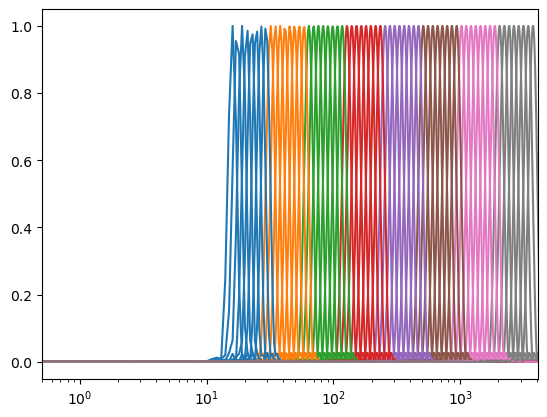

In [ ]:
spec = HYPERPARAMS
cqt_params = {
    "sr": spec["sr"],
    "bins_per_octave": spec["bins_per_octave"],
    "hop_length": spec["hop_length"],
    "n_bins": spec["n_bins"],
    "fmin": spec["fmin"],
    # "fmax": spec["fmax"],
}
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
closure = CQT(**cqt_params)
cqt_kernels_real = closure.cqt_kernels_real
cqt_kernels_imag = closure.cqt_kernels_imag
for q in range(spec["bins_per_octave"]):
    for j in range(spec["n_octave"]):
        plt.semilogx(torch.abs(torch.fft.fft(torch.complex(cqt_kernels_real[j*spec["bins_per_octave"]+q,...].squeeze(),cqt_kernels_imag[j*spec["bins_per_octave"]+q,...].squeeze()))), color = col[j])
plt.xlim(0.5, cqt_kernels_real.shape[-1]//2)

In [ ]:
# murenn_init = MuReNN(spec=HYPERPARAMS)
# N = HYPERPARAMS["seg_length"]//2
# dirac = torch.zeros((1, 1, N))
# dirac[0, 0, N//2] = 1.0
# phi, x_levels = murenn_init.tfm(dirac)
# zeros_phi = phi.new_zeros(size=phi.shape)
# J = len(x_levels)
# inv = IDTCWT(
#     J=J,
#     alternate_gh=False,
# )
# murenn_imp = []
# for j in range(J):
#     for k in range(murenn_init.psis[j].out_channels):
#         x_level = x_levels[j].type(torch.complex64)
#         murenn_psi = murenn_init.psis[j]
#         y_real = murenn_psi(x_level.real)[0, k, :].reshape(1,1,-1)
#         y_imag = murenn_psi(x_level.imag)[0, k, :].reshape(1,1,-1)
#         y = y_real + 1j * y_imag
#         Wpsis_ji = [y if i == j else x_levels[i].new_zeros(size=x_levels[i].shape) for i in range(J)]
#         y_inv = inv(zeros_phi, Wpsis_ji).detach()
#         murenn_imp.append(y_inv)

In [ ]:
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
for j in range(8):
    for i in range(8):
        plt.semilogx(torch.abs(torch.fft.fft(murenn_imp[j*8+i].detach().squeeze())),color = col[j])
        plt.xlim(0.5,N//2)


NameError: name 'murenn_imp' is not defined

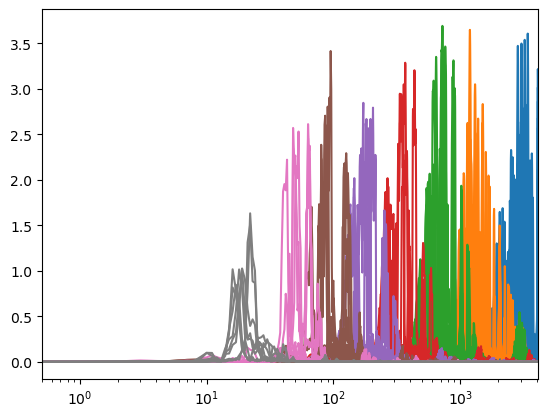

In [ ]:
# col = [
#     'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
#     'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
# for j in range(8):
#     for i in range(8):
#         plt.semilogx(torch.abs(torch.fft.fft(murenn_imp[j*8+i].detach().squeeze())),color = col[j])
#         plt.xlim(0.5,N//2)
